T1: Red Compartida 

In [2]:
import torch, torch.nn as nn, numpy as np, gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Categorical

class ActorCriticNet(nn.Module):
    def __init__(self, state_dim, n_actions, hidden=256):
        super().__init__()
        self.tronco = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden),    nn.Tanh(),
        )
        self.cabeza_actor   = nn.Linear(hidden, n_actions)
        self.cabeza_critico = nn.Linear(hidden, 1)

    def forward(self, x):
        feat  = self.tronco(x)
        dist  = Categorical(logits=self.cabeza_actor(feat))
        value = self.cabeza_critico(feat).squeeze(-1)
        return dist, value

# ── Setup y verificacion ──────────────────────────────────────
env      = gym.make("CartPole-v1")
model    = ActorCriticNet(4, 2, hidden=256)
optimizer= torch.optim.Adam(model.parameters(), lr=1e-3)

s = torch.FloatTensor(env.reset()[0]).unsqueeze(0)  # (1, 4)
dist, val = model(s)
print(f"Acciones: {dist.probs.detach().numpy().round(3)}")
print(f"Valor V(s): {val.item():.4f}")
print(f"Entropia H(pi): {dist.entropy().item():.4f}")
print(f"Entropia maxima (uniforme): {torch.log(torch.tensor(2.0)):.4f}")


Acciones: [[0.49 0.51]]
Valor V(s): -0.1394
Entropia H(pi): 0.6929
Entropia maxima (uniforme): 0.6931


T2: Loop A2C

In [5]:
def train_a2c_episode(env, model, optimizer, gamma=0.99,
                       c_v=0.5, c_e=0.01, max_grad_norm=0.5):
    """Un episodio completo de A2C. Retorna metricas."""
    log_probs, values, rewards, entropies = [], [], [], []
    obs, _ = env.reset(); done = False

    while not done:
        s    = torch.FloatTensor(obs)
        dist, val = model(s)
        action    = dist.sample()
        obs, r, term, trunc, _ = env.step(action.item())
        done = term or trunc
        log_probs.append(dist.log_prob(action))
        values.append(val)
        rewards.append(r)
        entropies.append(dist.entropy())   # H(π) diferenciable

    # ── Retornos G_t descontados (recorrido inverso) ──────────
    G, returns = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G; returns.insert(0, G)
    returns = torch.tensor(returns, dtype=torch.float32)
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    log_probs = torch.stack(log_probs)
    values    = torch.stack(values)
    entropies = torch.stack(entropies)
    advantages = returns - values.detach()   # A_t = G_t - V(s_t)

    # ── 3 losses ─────────────────────────────────────────────
    L_actor   = -(log_probs * advantages).mean()
    L_critic  = c_v * (returns - values).pow(2).mean()
    L_entropy = -c_e * entropies.mean()
    L_total   = L_actor + L_critic + L_entropy

    optimizer.zero_grad(); L_total.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
    optimizer.step()

    return (sum(rewards), L_actor.item(), L_critic.item(),
            entropies.mean().item())


T3:     Entrenar y Graficar 

In [4]:
# Entrenar A2C por 1000 episodios
N_EP   = 1000
hist   = {"reward":[], "L_actor":[], "L_critic":[], "entropy":[]}

for ep in range(N_EP):
    r, la, lc, h = train_a2c_episode(env, model, optimizer)
    hist["reward"].append(r)
    hist["L_actor"].append(la)
    hist["L_critic"].append(lc)
    hist["entropy"].append(h)
    if ep % 100 == 0:
        print(f"Ep {ep:>4d} | R={np.mean(hist['reward'][-20:]):>7.1f} | "
              f"H={np.mean(hist['entropy'][-20:]):.4f} | "
              f"L_a={np.mean(hist['L_actor'][-20:]):.4f}")


Ep    0 | R=   46.0 | H=0.6931 | L_a=0.1018
Ep  100 | R=   41.5 | H=0.5164 | L_a=0.0206
Ep  200 | R=  229.2 | H=0.5015 | L_a=-0.2701
Ep  300 | R=  210.9 | H=0.5572 | L_a=-0.0275
Ep  400 | R=  359.4 | H=0.5295 | L_a=-0.1974
Ep  500 | R=  321.9 | H=0.4929 | L_a=0.1302
Ep  600 | R=  153.3 | H=0.3839 | L_a=-0.0312
Ep  700 | R=  286.4 | H=0.4609 | L_a=0.0542
Ep  800 | R=  499.9 | H=0.3490 | L_a=0.0219
Ep  900 | R=  430.4 | H=0.3952 | L_a=-0.0163


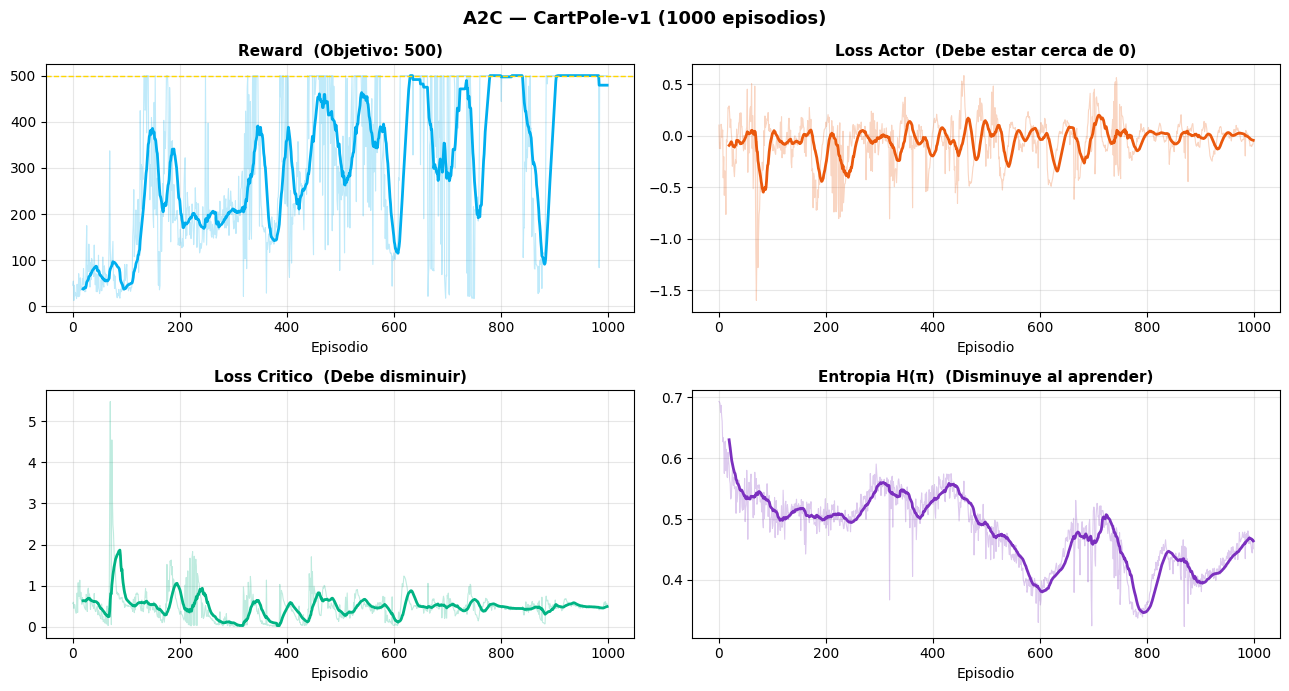

In [9]:
def plot_a2c_metrics(hist, window=20, title="A2C — CartPole-v1"):
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))
    metrics = [
        ("reward",  "Reward",       "#00AEEF", f"Objetivo: 500"),
        ("L_actor", "Loss Actor",   "#EA580C", "Debe estar cerca de 0"),
        ("L_critic","Loss Critico", "#00B383", "Debe disminuir"),
        ("entropy", "Entropia H(π)","#7B2FBE", "Disminuye al aprender"),
    ]
    for ax, (key, label, color, nota) in zip(axes.flat, metrics):
        vals = np.array(hist[key])
        ma   = np.convolve(vals, np.ones(window)/window, mode='valid')
        ax.plot(vals, alpha=0.25, color=color, linewidth=0.8)
        ax.plot(range(window-1, len(vals)), ma, color=color, linewidth=2)
        ax.set_title(f"{label}  ({nota})", fontsize=11, fontweight='bold')
        ax.set_xlabel("Episodio"); ax.grid(alpha=0.3)
        if key == "reward":
            ax.axhline(500, color='gold', linestyle='--', lw=1)
    fig.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

plot_a2c_metrics(hist, window=20, title="A2C — CartPole-v1 (1000 episodios)")


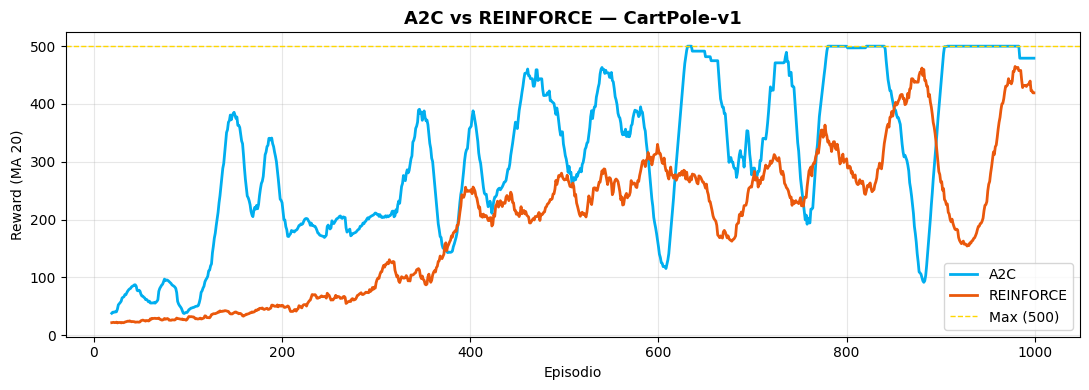

In [7]:
# Reutilizar rewards_no_baseline del Lab 9B (si los tienes)
# Si no, re-entrenar REINFORCE rapido:
def reinforce_simple(env, n_ep=1000, gamma=0.99, lr=1e-3):
    """REINFORCE sin baseline — referencia."""
    from torch.optim import Adam
    pol  = nn.Sequential(nn.Linear(4,128),nn.ReLU(),nn.Linear(128,2))
    opt  = Adam(pol.parameters(), lr=lr)
    hist_r = []
    for _ in range(n_ep):
        log_ps, rews = [], []
        obs, _ = env.reset()
        while True:
            d = Categorical(logits=pol(torch.FloatTensor(obs)))
            a = d.sample(); obs,r,te,tr,_ = env.step(a.item())
            log_ps.append(d.log_prob(a)); rews.append(r)
            if te or tr: break
        G, rets = 0, []
        for r in reversed(rews): G=r+gamma*G; rets.insert(0,G)
        rets = torch.tensor(rets, dtype=torch.float32)
        rets = (rets-rets.mean())/(rets.std()+1e-8)
        loss = -(torch.stack(log_ps)*rets).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        hist_r.append(sum(rews))
    return hist_r

rewards_reinforce = reinforce_simple(env, n_ep=1000)

# Graficar ambos en una figura
fig, ax = plt.subplots(figsize=(11, 4))
window  = 20
for rewards, label, color in [
    (hist["reward"],    "A2C",       "#00AEEF"),
    (rewards_reinforce, "REINFORCE", "#EA580C"),
]:
    ma = np.convolve(rewards, np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(rewards)), ma, color=color, lw=2, label=label)
ax.axhline(500, color='gold', linestyle='--', lw=1, label='Max (500)')
ax.set_title("A2C vs REINFORCE — CartPole-v1", fontweight='bold', fontsize=13)
ax.set_xlabel("Episodio"); ax.set_ylabel("Reward (MA 20)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


T4: Entropia

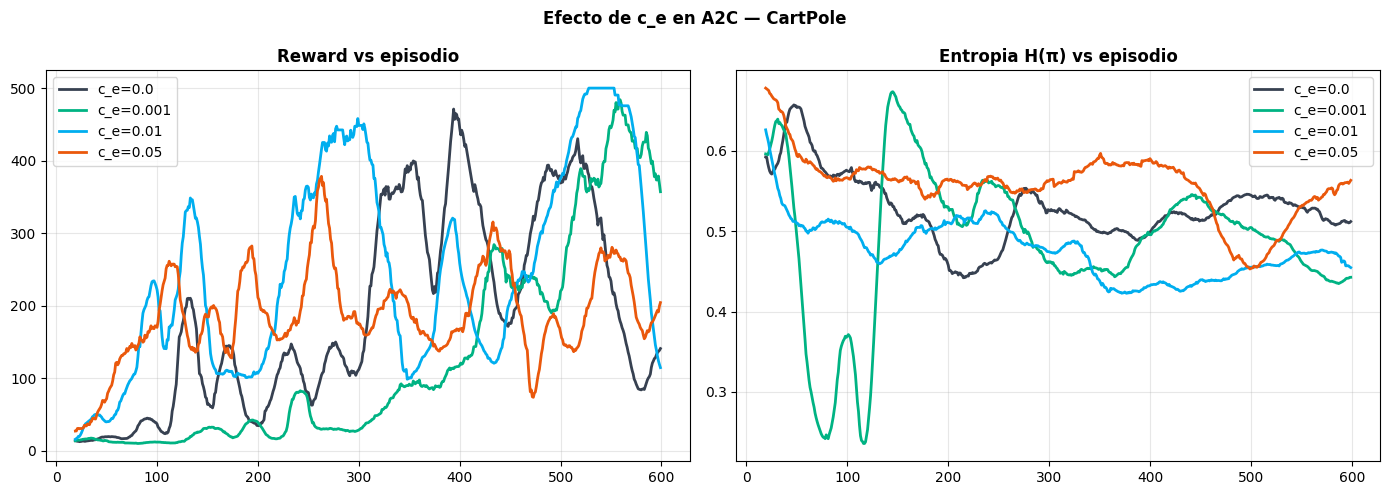

In [27]:
# Variar c_e y comparar
ce_values = [0.0, 0.001, 0.01, 0.05]
results_ce = {}

for c_e in ce_values:
    model_ce = ActorCriticNet(4, 2, hidden=256)
    opt_ce   = torch.optim.Adam(model_ce.parameters(), lr=1e-3)
    rewards_ce, entropies_ce = [], []

    for ep in range(600):
        r, _, _, h = train_a2c_episode(
            env, model_ce, opt_ce, c_e=c_e)
        rewards_ce.append(r); entropies_ce.append(h)

    results_ce[c_e] = {"rewards": rewards_ce, "entropies": entropies_ce}

# Graficar reward vs episodio para cada c_e
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = {0.0:"#374151", 0.001:"#00B383", 0.01:"#00AEEF", 0.05:"#EA580C"}
for c_e, data in results_ce.items():
    ma_r = np.convolve(data["rewards"],   np.ones(20)/20, mode='valid')
    ma_h = np.convolve(data["entropies"], np.ones(20)/20, mode='valid')
    ax1.plot(range(19,600), ma_r, color=colors[c_e], lw=2, label=f"c_e={c_e}")
    ax2.plot(range(19,600), ma_h, color=colors[c_e], lw=2, label=f"c_e={c_e}")
ax1.set_title("Reward vs episodio",       fontweight='bold'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.set_title("Entropia H(π) vs episodio",fontweight='bold'); ax2.legend(); ax2.grid(alpha=0.3)
plt.suptitle("Efecto de c_e en A2C — CartPole", fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()
